In [1]:
import numpy as np
import numpy.linalg as la
import pickle as pkl
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import collections as mc
from scipy.spatial.distance import cdist
from scipy.optimize import linprog
from scipy.linalg import block_diag
from dataclasses import dataclass
from copy import copy, deepcopy
#from numba import prange, guvectorize, float64
import math
import pandas as pd

In [2]:
radius = 1.         # Radius of cells
a = 6              # ATP required per fixed C
b = 5              # ATP per C in respiration
c = 6/10           # ATP produced per photon  
d = 38 #53              # ATP per g of DW of biomass
xi = 41             # mmol of C /g of DW


In [3]:
def calculate_distances(cells_pos, window_size=50, dim=2):
    num_cells = len(cells_pos)
    distances = np.identity(num_cells)
    for i,cell1 in enumerate(cells_pos):
        for j,cell2 in enumerate(cells_pos):
            if i==j:
                distances[i][j] = window_size*10000
            else:
                if dim == 3: 
                    dx = abs(cell2[0] - cell1[0])
                    if dx > window_size/2:
                        dx = window_size - dx
                    dy = abs(cell2[1] - cell1[1])
                    if dy > window_size/2:
                        dy = window_size - dy
                    dz = abs(cell2[2] - cell1[2])
                    if dz > window_size/2:
                        dz = window_size - dz
                    distances[i][j] = math.sqrt(dx ** 2 + dy ** 2 + dz ** 2)
                else: 
                    distances[i][j] = math.sqrt((cell2[0] - cell1[0]) ** 2 + (cell2[1] - cell1[1]) ** 2 +
                                                (cell2[2] - cell1[2]) ** 2)
    return distances

            
def place_cells(num_cells, window_size=50, overlap=False, dim=2):
    min_sep = 2*radius
    rng = np.random.default_rng()
    cells_pos = rng.random((1, dim)) * (window_size)
    while len(cells_pos)<num_cells:
        new_pos =  rng.random((1, dim)) * (window_size)
        if not overlap: 
            cells_pos_new = np.vstack((cells_pos, new_pos))
            distances = calculate_distances(cells_pos_new, window_size, dim)
            if all(np.concatenate(distances)>min_sep):
                print(len(distances))
                cells_pos = cells_pos_new
            else:
                print(distances)
        else:
            cells_pos_new = np.vstack((cells_pos, new_pos))
            cells_pos = cells_pos_new
            
    return cells_pos



def A_matrix(cells_pos, window_size, dim):
    distances = calculate_distances(cells_pos, window_size, dim)
    num_cells = cells_pos.shape[0]
    A = np.identity(num_cells)
    for i in range(0,num_cells):
        for j in range(0,num_cells):
            if i!=j:
                A[i][j] = radius/distances[i][j]
    
    return A



In [4]:
results = pd.read_csv('/home/arianferrero/Documentos/TESIS/synechocystis/single_cell_metabolic_flux_analysis/results_new/results_std_corrected_12h_PEAKS.dat', sep = '\t')
results



,r_C,r_N,u_C,u_N,g,sd
0,0.061354,0.100474,2.519806,0.826900,0.060653,0.000706
1,0.057014,0.112534,2.341554,0.926153,0.056249,0.000771
2,0.011694,0.051683,0.480267,0.425351,0.009837,0.001816
3,0.014260,0.056870,0.585652,0.468042,0.012470,0.001793
4,0.014630,0.055157,0.600838,0.453945,0.012851,0.001785
...,...,...,...,...,...,...
515,0.005781,0.069327,0.237443,0.570559,0.004094,0.001397
516,0.000010,0.032722,0.000411,0.269305,0.000005,0.000003
517,0.054587,0.126257,2.241893,1.039095,0.053784,0.000809
518,0.000010,0.044336,0.000411,0.364886,0.000005,0.000003


In [5]:
cells_pos = place_cells(520,window_size= 373, overlap=False, dim=3)
distances = calculate_distances(cells_pos)
np.fill_diagonal(distances, radius)
distances

2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
277
27

array([[  1.        ,  86.40557994, 392.44478338, ..., 185.00063707,
        227.94964883, 341.13245398],
       [ 86.40557994,   1.        , 360.00672164, ..., 139.12935635,
        220.88546163, 333.08156805],
       [392.44478338, 360.00672164,   1.        , ..., 427.29978614,
        489.20413745, 231.31105405],
       ...,
       [185.00063707, 139.12935635, 427.29978614, ...,   1.        ,
        111.58761371, 346.05935751],
       [227.94964883, 220.88546163, 489.20413745, ..., 111.58761371,
          1.        , 354.74325863],
       [341.13245398, 333.08156805, 231.31105405, ..., 346.05935751,
        354.74325863,   1.        ]], shape=(520, 520))

In [ ]:
cells_pos

NameError: name 'cells_pos' is not defined

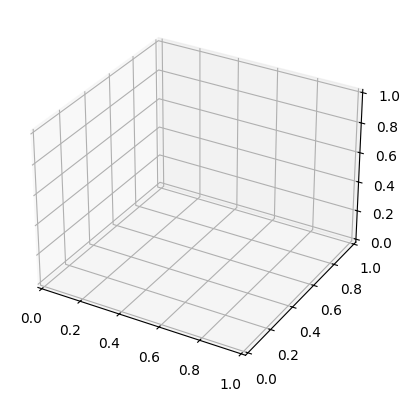

In [11]:

import matplotlib.pyplot as plt
import numpy as np

# Fixing random state for reproducibility
np.random.seed(19680801)


fig = plt.figure()
ax = fig.add_subplot(projection='3d')

xs = [i[0] for i in cells_pos]
ys = [i[1] for i in cells_pos]
zs = [i[2] for i in cells_pos]
ax.scatter(xs, ys, zs, s=50)

ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')
plt.rcParams['figure.figsize'] = [14,14]
plt.show()


In [6]:
pd.DataFrame(cells_pos).to_csv('cells_pos_3D_2.dat', sep = '\t', header=False, index=False)

In [7]:
n_cells = 520

N1 = []
for i in range(n_cells): 
    n = []
    for j in range(0,3*n_cells):
        if j == i*3:
            n.append(1.)
        else: 
            n.append(0.)
    N1.append(n)
N1 = np.array(N1)
N1

array([[1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.]], shape=(520, 1560))

In [8]:
N2 = []
for i in range(n_cells): 
    n = []
    for j in range(0,3*n_cells):
        if j == i*3+1:
            n.append(1.)
        else: 
            n.append(0.)
    N2.append(n)
N2 = np.array(N2)
N2

array([[0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.]], shape=(520, 1560))

In [9]:
N3 = []
for i in range(n_cells): 
    n = []
    for j in range(0,3*n_cells):
        if j == i*3+2:
            n.append(1.)
        else: 
            n.append(0.)
    N3.append(n)
N3 = np.array(N3)
N3

array([[0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.]], shape=(520, 1560))

In [10]:
#    u_C (inorg)    u_o     gamma     lambda
# f_ATP = - a*u_c + b*u_o + c*gamma - d*lambda

a = 6
b = 5
c = 6/10
d = 38 #53


N4 = []
for i in range(n_cells): 
    n = []
    for j in range(0,3*n_cells):
        if j == i*3:
            n.append(-a)
        elif j == i*3+1:
            n.append(b)
        elif j == i*3+2:
            n.append(c)
        else: 
            n.append(0.)
    N4.append(n)
N4 = np.array(N4)
N4

array([[-6. ,  5. ,  0.6, ...,  0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
       ...,
       [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. , ..., -6. ,  5. ,  0.6]], shape=(520, 1560))

In [11]:
# acetate = -u_c + u_o + xi*lambda

N5 = []
for i in range(n_cells): 
    n = []
    for j in range(0,n_cells):
        n += [1, -1, 0]
    N5.append(n)
    
N5 = np.array(N5)
N5

array([[ 1, -1,  0, ...,  1, -1,  0],
       [ 1, -1,  0, ...,  1, -1,  0],
       [ 1, -1,  0, ...,  1, -1,  0],
       ...,
       [ 1, -1,  0, ...,  1, -1,  0],
       [ 1, -1,  0, ...,  1, -1,  0],
       [ 1, -1,  0, ...,  1, -1,  0]], shape=(520, 1560))

In [12]:
cell_pos = np.loadtxt('cells_pos_3D_2.dat')
distances = calculate_distances(cell_pos)
np.fill_diagonal(distances, radius)
distances

array([[  1.        ,  86.40557994, 392.44478338, ..., 185.00063707,
        227.94964883, 341.13245398],
       [ 86.40557994,   1.        , 360.00672164, ..., 139.12935635,
        220.88546163, 333.08156805],
       [392.44478338, 360.00672164,   1.        , ..., 427.29978614,
        489.20413745, 231.31105405],
       ...,
       [185.00063707, 139.12935635, 427.29978614, ...,   1.        ,
        111.58761371, 346.05935751],
       [227.94964883, 220.88546163, 489.20413745, ..., 111.58761371,
          1.        , 354.74325863],
       [341.13245398, 333.08156805, 231.31105405, ..., 346.05935751,
        354.74325863,   1.        ]], shape=(520, 520))

In [13]:
distances_ext = []

for i in distances:
    d = []
    for j in i:
        for r in range(3):
            d.append(j)
    distances_ext.append(d)
distances_ext = np.array(distances_ext)
distances_ext

array([[  1.        ,   1.        ,   1.        , ..., 341.13245398,
        341.13245398, 341.13245398],
       [ 86.40557994,  86.40557994,  86.40557994, ..., 333.08156805,
        333.08156805, 333.08156805],
       [392.44478338, 392.44478338, 392.44478338, ..., 231.31105405,
        231.31105405, 231.31105405],
       ...,
       [185.00063707, 185.00063707, 185.00063707, ..., 346.05935751,
        346.05935751, 346.05935751],
       [227.94964883, 227.94964883, 227.94964883, ..., 354.74325863,
        354.74325863, 354.74325863],
       [341.13245398, 341.13245398, 341.13245398, ...,   1.        ,
          1.        ,   1.        ]], shape=(520, 1560))

In [14]:
N5 = N5/distances_ext * radius
for i,cell in enumerate(N5): 
    if i == 0:
        N5[i,0] = 1
        N5[i,1] = -1
        N5[i,2] = 0
    else: 
        for j in range(n_cells*3): 
            if j == i*3:
                N5[i,j] = 1
            elif j == i*3+1:
                N5[i,j] = -1
            elif j == i*3+2:
                N5[i,j] = 0
            elif j == i*3+3:
                N5[i,j] = xi
                
        
N5 = np.around(N5, decimals=6)
N5

array([[ 1.0000e+00, -1.0000e+00,  0.0000e+00, ...,  2.9310e-03,
        -2.9310e-03,  0.0000e+00],
       [ 1.1573e-02, -1.1573e-02,  0.0000e+00, ...,  3.0020e-03,
        -3.0020e-03,  0.0000e+00],
       [ 2.5480e-03, -2.5480e-03,  0.0000e+00, ...,  4.3230e-03,
        -4.3230e-03,  0.0000e+00],
       ...,
       [ 5.4050e-03, -5.4050e-03,  0.0000e+00, ...,  2.8900e-03,
        -2.8900e-03,  0.0000e+00],
       [ 4.3870e-03, -4.3870e-03,  0.0000e+00, ...,  4.1000e+01,
        -2.8190e-03,  0.0000e+00],
       [ 2.9310e-03, -2.9310e-03,  0.0000e+00, ...,  1.0000e+00,
        -1.0000e+00,  0.0000e+00]], shape=(520, 1560))

In [15]:
# u_o + xi*lambda = u_c + acetate 
# u_o + xi*lambda >= nanoSIMS value 
# u_o >= nanoSIMS vlue - xi*lambda

N6 = []

for i in range(n_cells): 
    n = []
    for j in range(0,n_cells):
        n += [2, -1, 0]
    N6.append(n)
    
N6 = np.array(N6)

N6

array([[ 2, -1,  0, ...,  2, -1,  0],
       [ 2, -1,  0, ...,  2, -1,  0],
       [ 2, -1,  0, ...,  2, -1,  0],
       ...,
       [ 2, -1,  0, ...,  2, -1,  0],
       [ 2, -1,  0, ...,  2, -1,  0],
       [ 2, -1,  0, ...,  2, -1,  0]], shape=(520, 1560))

In [16]:
N7 = []
for j in range(0,n_cells):
    N7 += [1, -1, 0]
N7 = np.array([N7])

In [17]:
matrix = np.concatenate([N1,N2,N3,N4,N5,N7])

In [18]:
matrix

array([[ 1.000e+00,  0.000e+00,  0.000e+00, ...,  0.000e+00,  0.000e+00,
         0.000e+00],
       [ 0.000e+00,  0.000e+00,  0.000e+00, ...,  0.000e+00,  0.000e+00,
         0.000e+00],
       [ 0.000e+00,  0.000e+00,  0.000e+00, ...,  0.000e+00,  0.000e+00,
         0.000e+00],
       ...,
       [ 4.387e-03, -4.387e-03,  0.000e+00, ...,  4.100e+01, -2.819e-03,
         0.000e+00],
       [ 2.931e-03, -2.931e-03,  0.000e+00, ...,  1.000e+00, -1.000e+00,
         0.000e+00],
       [ 1.000e+00, -1.000e+00,  0.000e+00, ...,  1.000e+00, -1.000e+00,
         0.000e+00]], shape=(2601, 1560))

In [19]:
np.savetxt('autotroph_matrix.dat', matrix, delimiter='\t', fmt='%10.4f'  )

In [20]:
#results = pd.read_csv('/home/arianferrero/Documentos/TESIS/synechocystis/single_cell_metabolic_flux_analysis/results/results_std_corrected.dat', sep = '\t')
n_cells = 520

#b1_min = [0 for i in range(n_cells)]

fba_max = 0.6*23/(41*6+38)

b1_min = []
for cell in results.iterrows():
    #b1_max.append(cell[1]['u_C'])
    if cell[1]['g']<fba_max:
        b1_min.append(cell[1]['u_C'])
    else: 
        b1_min.append(0)

b2_min = []
for cell in results.iterrows():
    if cell[1]['g']<fba_max:
        b1_min.append(0)
    else: 
        b1_min.append(max(0,cell[1]['u_C'] - 41*cell[1]['g']))
   # b2_min.append(max(0,cell[1]['u_C'] - 41*cell[1]['g']))
    #b2_min.append(0)


b3_min = [0 for i in range(n_cells)]

b4_min = []
for cell in results.iterrows():
    b4_min.append(38*cell[1]['g'])

b5_min = []
i = 0
for cell_i in results.iterrows():
    min_val = 41*cell_i[1]['g']
    j = 0
    for cell_j in results.iterrows():
        if i != j:
            min_val += 41*cell_j[1]['g']/distances[i][j]*radius
        j += 1
    i+= 1
    b5_min.append(min_val)



#b6_min = []
#for cell in results.iterrows():
#   b6_min.append(max(0,cell[1]['u_C'] - 41*cell[1]['g']))
#    

b7_min = [41*(np.sum(results['g']))]


#fba_max =  1000 #0.6*23/(41*6+38)
b1_max = []
for cell in results.iterrows():
    b1_max.append(20)
    #if cell[1]['g']<fba_max:
    #    b1_max.append(20)
    #else: 
    #    b1_max.append(cell[1]['u_C'])
    

b2_max = []
for cell in results.iterrows():
   # b2_max.append(cell[1]['u_C']-42*cell[1]['g'])
    b2_max.append(3.37)

    
b3_max = [23 for i in range(n_cells)]
b4_max = [20 for i in range(n_cells)]
b5_max = [1000 for i in range(n_cells)]
#b6_max = [20 for i in range(n_cells)]
b7_max = [50000]

b_min = b1_min+b2_min+b3_min+b4_min+b5_min+b7_min
b_max = b1_max+b2_max+b3_max+b4_max+b5_max+b7_max

In [21]:
bounds = np.array([b_min, b_max]).transpose()

In [20]:
0.6*23/(41*6+38)

0.048591549295774646

In [22]:
np.savetxt('bounds.dat', bounds, delimiter='\t', fmt='%10.4f'  )

In [23]:
matrix.shape

(2601, 1560)

In [24]:
"""
Flux Balance Analysis (FBA) via linear programming for the autotroph model.

Data layout
-----------
autotroph_matrix.dat : (2601 x 1560) matrix A
bounds.dat           : (2601 x 2)    matrix of [lower, upper] bounds, ROW-ALIGNED with A

The 1560 columns of A are the decision (flux) variables:
    3 independent variables (u_c, u_o, gamma) x 520 grid cells,
    ordered column-major per cell: col 3*i+0 = u_c(cell i), 3*i+1 = u_o(cell i), 3*i+2 = gamma(cell i)

The 2601 rows of A are linear constraints on those variables, and bounds.dat gives the
lower/upper bound for each row, i.e. this is a "range-constraint" LP:

    lb_row  <=  (A @ x)_row  <=  ub_row      for every row

(Inspecting the data confirms this: the first 1560 rows are each a single 1.0 in one
column -- i.e. they simply encode the box bounds 0 <= u_c,u_o <= 10 and 0 <= gamma <= 23
for every cell as constraint rows rather than as separate variable bounds. The remaining
rows combine 3 or ~1040 variables per row and encode per-cell and network-wide budgets.)

Because the variable bounds are already embedded as rows, the flux vector x itself is
left free/unbounded in the LP -- all restriction on x comes from the row constraints.

Usage
-----
    python fba_lp.py

Edit OBJECTIVE_INDEX / build_objective() below to change what gets maximized.
"""

import numpy as np
import scipy.sparse as sp
from scipy.optimize import linprog

MATRIX_FILE = "autotroph_matrix.dat"
BOUNDS_FILE = "bounds.dat"

N_CELLS = 520
VAR_NAMES = ["u_c", "u_o", "gamma"]
N_VARS = len(VAR_NAMES)
N = N_CELLS * N_VARS


def load_problem(matrix_file=MATRIX_FILE, bounds_file=BOUNDS_FILE):
    """Load the constraint matrix and row bounds."""
    A = np.loadtxt(matrix_file)
    bnd = np.loadtxt(bounds_file)
    lb, ub = bnd[:, 0], bnd[:, 1]

    if A.shape[1] != N:
        raise ValueError(f"expected {N} columns (={N_VARS}x{N_CELLS}), got {A.shape[1]}")
    if A.shape[0] != bnd.shape[0]:
        raise ValueError("matrix and bounds files must have the same number of rows")

    return sp.csr_matrix(A), lb, ub


def build_range_constraints(A, lb, ub):
    """
    Turn the two-sided row constraints  lb <= A x <= ub  into scipy.optimize.linprog's
    one-sided form  A_ub x <= b_ub  by stacking (A; -A) against (ub; -lb).
    Rows with lb == -inf / ub == +inf are dropped from the respective half automatically.
    """
    finite_ub = np.isfinite(ub)
    finite_lb = np.isfinite(lb)

    A_top, b_top = A[finite_ub], ub[finite_ub]
    A_bot, b_bot = -A[finite_lb], -lb[finite_lb]

    A_ineq = sp.vstack([A_top, A_bot]).tocsr()
    b_ineq = np.concatenate([b_top, b_bot])
    return A_ineq, b_ineq


def run_fba(A, lb, ub, objective, sense="max", var_bounds=(None, None)):
    """
    Solve   sense objective^T x   subject to   lb <= A x <= ub.

    objective : length-N array of coefficients (e.g. e_0 to optimize the first variable)
    sense     : "max" or "min"
    var_bounds: box bounds passed straight to linprog for x itself (default: free,
                since the box bounds are already encoded as rows of A in this dataset)
    """
    c = -np.asarray(objective, dtype=float) if sense == "max" else np.asarray(objective, dtype=float)
    A_ineq, b_ineq = build_range_constraints(A, lb, ub)

    res = linprog(c, A_ub=A_ineq, b_ub=b_ineq, bounds=var_bounds, method="highs")
    if res.success:
        res.objective_value = -res.fun if sense == "max" else res.fun
    return res


def diagnose_infeasibility(A, lb, ub, top_n=15):
    """
    If the LP is infeasible, find the minimal-total-violation relaxation:
        minimize   sum(s)
        s.t.       A x - s <= ub ,  -A x - s <= -lb ,  s >= 0
    and report which rows need slack (s > 0) and by how much. Useful for pinpointing
    which constraints in the .dat files are inconsistent with the rest.
    """
    m, n = A.shape
    I = sp.identity(m, format="csr")
    A_ub = sp.vstack([
        sp.hstack([A, -I]),
        sp.hstack([-A, -I]),
    ]).tocsr()
    b_ub = np.concatenate([ub, -lb])
    c = np.concatenate([np.zeros(n), np.ones(m)])
    bounds = [(None, None)] * n + [(0, None)] * m

    res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")
    if not res.success:
        print("  (relaxation LP itself failed to solve:", res.message, ")")
        return

    s = res.x[n:]
    order = np.argsort(-s)
    offenders = [i for i in order if s[i] > 1e-6][:top_n]

    print(f"  total slack needed to become feasible: {res.fun:.4f}")
    print(f"  rows requiring relaxation: {int(np.sum(s > 1e-6))}")
    print(f"  {'row idx (0-based)':>18} | {'.dat line (1-based)':>20} | {'slack':>10} | {'lb':>10} | {'ub':>10}")
    for i in offenders:
        print(f"  {i:>18} | {i+1:>20} | {s[i]:>10.4f} | {lb[i]:>10.4f} | {ub[i]:>10.4f}")


def summarize_solution(x, n_print_cells=5):
    """Print the optimal flux table for the first few cells."""
    print(f"  {'cell':>5} | " + " | ".join(f"{v:>10}" for v in VAR_NAMES))
    for i in range(min(n_print_cells, N_CELLS)):
        vals = x[i * N_VARS:(i + 1) * N_VARS]
        print(f"  {i:>5} | " + " | ".join(f"{v:>10.4f}" for v in vals))
    if N_CELLS > n_print_cells:
        print(f"  ... ({N_CELLS - n_print_cells} more cells)")


if __name__ == "__main__":
    A, lb, ub = load_problem()

    # Objective: maximize the first variable (u_c of cell 0, column 0).
    objective = np.zeros(N)
    OBJECTIVE_INDEX = 0
    objective[OBJECTIVE_INDEX] = 1.0

    res = run_fba(A, lb, ub, objective, sense="min")

    if res.success:
        print(f"Status: optimal")
        print(f"Maximized value of x[{OBJECTIVE_INDEX}] "
              f"({VAR_NAMES[OBJECTIVE_INDEX % N_VARS]}, cell {OBJECTIVE_INDEX // N_VARS}): "
              f"{res.objective_value:.6f}\n")
        print("Optimal flux distribution (first cells):")
        summarize_solution(res.x)
    else:
        print(f"Status: {res.status} - {res.message}\n")
        print("The LP as specified by these two files is infeasible: no flux vector x")
        print("satisfies every row constraint lb <= (A x) <= ub simultaneously.\n")
        print("Diagnosing which row(s) are responsible (minimal-slack relaxation):")
        diagnose_infeasibility(A, lb, ub)

Status: optimal
Maximized value of x[0] (u_c, cell 0): 0.225335

Optimal flux distribution (first cells):
   cell |        u_c |        u_o |      gamma
      0 |     0.2253 |     0.0330 |     5.8197
      1 |     1.9732 |     0.0353 |    23.0000
      2 |     2.2377 |    -0.0000 |    23.0000
      3 |     2.2210 |    -0.0000 |    23.0000
      4 |     2.2186 |    -0.0000 |    23.0000
  ... (515 more cells)


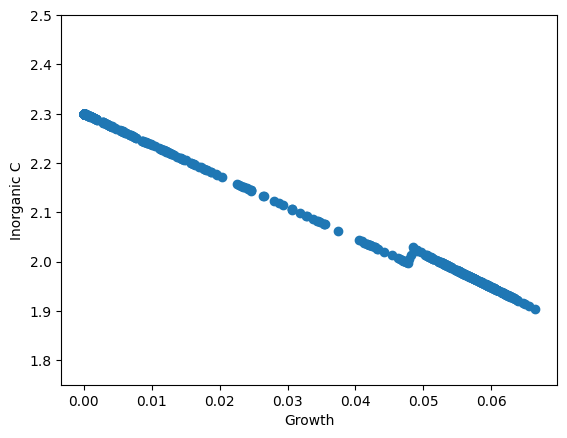

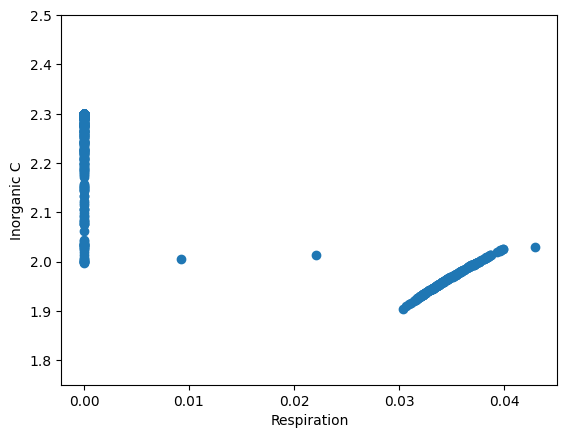

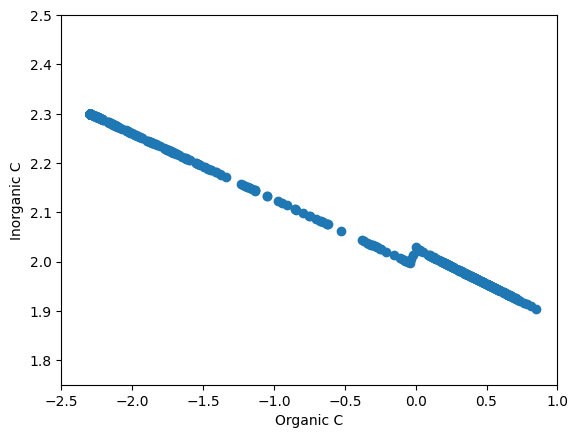

In [79]:
a = [i for i in range(0,len(res.x),3)]

ac = 41*results['g'] - res.x[a] + res.x[[i+1 for i in a]] 

plt.scatter(results['g'],res.x[a])
plt.ylim(1.75,2.5)
plt.xlabel('Growth')
plt.ylabel('Inorganic C')
plt.show()


plt.scatter(res.x[[i+1 for i in a]],res.x[a])
plt.ylim(1.75,2.5)
plt.xlabel('Respiration')
plt.ylabel('Inorganic C')
plt.show()


plt.scatter(ac,res.x[a])
plt.ylim(1.75,2.5)
plt.xlim(-2.5,1)

plt.xlabel('Organic C')
plt.ylabel('Inorganic C')
plt.show()

In [70]:
res.x[a]

array([ 6.7096449, 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.       ,
       23.       , 23.       , 23.       , 23.       , 23.    